In [1]:
!nvidia-smi

Thu Nov 19 13:50:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!git -C /content/Bonetest remote -v

fatal: cannot change to '/content/Bonetest': No such file or directory


In [3]:
!git -C /content/Bonetest branch -a

fatal: cannot change to '/content/Bonetest': No such file or directory


In [5]:
!git clone https://github.com/trishakunder/Bonetest.git /content/Bonetest

Cloning into '/content/Bonetest'...
remote: Enumerating objects: 1840, done.
remote: Counting objects: 100% (49/49), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 1840 (delta 34), reused 30 (delta 30), pack-reused 1791 (from 3)
Receiving objects: 100% (1840/1840), 399.15 MiB | 29.11 MiB/s, done.
Resolving deltas: 100% (192/192), done.
Updating files: 100% (1543/1543), done.


In [6]:
%cd /content/Bonetest

/content/Bonetest


In [7]:
!git remote add upstream https://github.com/manyaa133/Bonetest.git

In [8]:
!git remote -v

origin	https://github.com/trishakunder/Bonetest.git (fetch)
origin	https://github.com/trishakunder/Bonetest.git (push)
upstream	https://github.com/manyaa133/Bonetest.git (fetch)
upstream	https://github.com/manyaa133/Bonetest.git (push)


In [9]:
!git fetch --all
!git branch -a

Fetching origin
Fetching upstream
From https://github.com/manyaa133/Bonetest
 * [new branch]      bonetest-model-improvements -> upstream/bonetest-model-improvements
 * [new branch]      main       -> upstream/main
* main
  remotes/origin/HEAD -> origin/main
  remotes/origin/main
  remotes/origin/testmodel
  remotes/upstream/bonetest-model-improvements
  remotes/upstream/main


In [11]:
!git clone --branch bonetest-model-improvements https://github.com/trishakunder/Bonetest.git /content/Bonetest

fatal: destination path '/content/Bonetest' already exists and is not an empty directory.


In [12]:
%cd /content/Bonetest

/content/Bonetest


In [13]:
!git remote -v

origin	https://github.com/trishakunder/Bonetest.git (fetch)
origin	https://github.com/trishakunder/Bonetest.git (push)
upstream	https://github.com/manyaa133/Bonetest.git (fetch)
upstream	https://github.com/manyaa133/Bonetest.git (push)


In [14]:
!git branch --show-current

main


In [15]:
!git fetch origin

In [16]:
!git branch -r

  origin/HEAD -> origin/main
  origin/main
  origin/testmodel
  upstream/bonetest-model-improvements
  upstream/main


In [17]:
!git checkout -b train/person1-regression-model upstream/bonetest-model-improvements

branch 'train/person1-regression-model' set up to track 'upstream/bonetest-model-improvements'.
Switched to a new branch 'train/person1-regression-model'


In [18]:
!git branch -m train/regression-multimodal

In [19]:
!git branch --show-current

train/regression-multimodal


In [20]:
!pip install -q kaggle pyyaml joblib scikit-learn opencv-python-headless albumentations

In [21]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [22]:
import os

OUTPUT_DIR = "/content/drive/MyDrive/BoneTest/Regression_Multimodal"

os.makedirs(f"{OUTPUT_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{OUTPUT_DIR}/plots", exist_ok=True)

print("Output folders created successfully!")
print("Output directory:", OUTPUT_DIR)

Output folders created successfully!
Output directory: /content/drive/MyDrive/BoneTest/Regression_Multimodal


In [23]:
from google.colab import files
files.upload()

Saving kaggle (1).json to kaggle (1).json


{'kaggle (1).json': b'{"username":"trishakunder","key":"1773d0637c8112d2b4e0d06974c4870e"}'}

In [25]:
!mkdir -p ~/.kaggle
!cp "kaggle (1).json" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

In [26]:
!mkdir -p /content/rsna-bone-age

!kaggle datasets download \
-d kmader/rsna-bone-age \
-p /content/rsna-bone-age \
--unzip

Dataset URL: https://www.kaggle.com/datasets/kmader/rsna-bone-age
License(s): other
100% 9.29G/9.29G [01:37<00:00, 103MB/s]



In [27]:
import os

IMAGE_DIR = "/content/rsna-bone-age/boneage-training-dataset/boneage-training-dataset"

print("Image directory exists:", os.path.exists(IMAGE_DIR))

if os.path.exists(IMAGE_DIR):
    print("Total images:", len(os.listdir(IMAGE_DIR)))

Image directory exists: True
Total images: 12611


In [28]:
%cd /content/Bonetest

!ls ml/data/splits/

/content/Bonetest
manifest_hashes.json  test_manifest.csv  train_manifest.csv  val_manifest.csv


In [29]:
import hashlib
import json
import pandas as pd
from pathlib import Path

SPLITS_DIR = Path("/content/Bonetest/ml/data/splits")

with open(SPLITS_DIR / "manifest_hashes.json") as f:
    expected_hashes = json.load(f)

for key, filename in [
    ("train_manifest", "train_manifest.csv"),
    ("val_manifest", "val_manifest.csv"),
    ("test_manifest", "test_manifest.csv")
]:
    actual_hash = hashlib.sha256(
        (SPLITS_DIR / filename).read_bytes()
    ).hexdigest()

    assert actual_hash == expected_hashes[key]["sha256"]

train_df = pd.read_csv(SPLITS_DIR / "train_manifest.csv")
val_df = pd.read_csv(SPLITS_DIR / "val_manifest.csv")
test_df = pd.read_csv(SPLITS_DIR / "test_manifest.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

AssertionError: 

In [30]:
import hashlib
import json
from pathlib import Path

SPLITS_DIR = Path("/content/Bonetest/ml/data/splits")

with open(SPLITS_DIR / "manifest_hashes.json") as f:
    expected_hashes = json.load(f)

for key, filename in [
    ("train_manifest", "train_manifest.csv"),
    ("val_manifest", "val_manifest.csv"),
    ("test_manifest", "test_manifest.csv")
]:
    actual_hash = hashlib.sha256(
        (SPLITS_DIR / filename).read_bytes()
    ).hexdigest()

    expected_hash = expected_hashes[key]["sha256"]

    print("\nFile:", filename)
    print("Expected:", expected_hash)
    print("Actual:  ", actual_hash)
    print("Match:", actual_hash == expected_hash)


File: train_manifest.csv
Expected: 718bfc88b4b7f68617b5e3696e37f59c54dc162bc354f0fac25ac16a4164e347
Actual:   b1929118d7ff82edd46eb962f498df072d74e2f8f460eb7b20ea826eae29d225
Match: False

File: val_manifest.csv
Expected: c8e3270dd10690cf531c367b04071a4ad4558b3813552e6158457fd7f31effd7
Actual:   54b66acab8e1b64e317d8b128df1c872adb62f3371b313de6de3d88e132a9f75
Match: False

File: test_manifest.csv
Expected: 70a26d0db0e7c9ebab855a64d918be1f9299280ce623444af902af4eca4ce823
Actual:   711838b889949f11b12531164521011af95a19226e96351e8db49ba6a58ea0fc
Match: False


In [31]:
%cd /content/Bonetest

!git status --short

/content/Bonetest
?? "kaggle (1).json"


In [32]:
!git log -1 --oneline

312bed9 (HEAD -> train/regression-multimodal, upstream/bonetest-model-improvements) Update BoneTest models, evaluation and Colab training pipeline


In [33]:
!git ls-files ml/data/splits/

ml/data/splits/manifest_hashes.json
ml/data/splits/test_manifest.csv
ml/data/splits/train_manifest.csv
ml/data/splits/val_manifest.csv


In [34]:
!git fetch upstream bonetest-model-improvements

From https://github.com/manyaa133/Bonetest
 * branch            bonetest-model-improvements -> FETCH_HEAD


In [35]:
!git show upstream/bonetest-model-improvements:ml/data/splits/manifest_hashes.json

{
  "train_manifest": {
    "path": "C:\\Bonetest\\ml\\data\\splits\\train_manifest.csv",
    "sha256": "718bfc88b4b7f68617b5e3696e37f59c54dc162bc354f0fac25ac16a4164e347",
    "rows": 10068
  },
  "val_manifest": {
    "path": "C:\\Bonetest\\ml\\data\\splits\\val_manifest.csv",
    "sha256": "c8e3270dd10690cf531c367b04071a4ad4558b3813552e6158457fd7f31effd7",
    "rows": 1259
  },
  "test_manifest": {
    "path": "C:\\Bonetest\\ml\\data\\splits\\test_manifest.csv",
    "sha256": "70a26d0db0e7c9ebab855a64d918be1f9299280ce623444af902af4eca4ce823",
    "rows": 1259
  }
}

In [36]:
import pandas as pd
from pathlib import Path

SPLITS_DIR = Path("/content/Bonetest/ml/data/splits")

for filename in [
    "train_manifest.csv",
    "val_manifest.csv",
    "test_manifest.csv"
]:
    df = pd.read_csv(SPLITS_DIR / filename)
    print(filename, ":", len(df))
    print("Columns:", df.columns.tolist())

train_manifest.csv : 10068
Columns: ['id', 'boneage', 'male', 'age_bin', 'strata', 'file_name', 'sha256']
val_manifest.csv : 1259
Columns: ['id', 'boneage', 'male', 'age_bin', 'strata', 'file_name', 'sha256']
test_manifest.csv : 1259
Columns: ['id', 'boneage', 'male', 'age_bin', 'strata', 'file_name', 'sha256']


In [37]:
%cd /content/Bonetest
!git status --short

/content/Bonetest
?? "kaggle (1).json"


In [38]:
!git log -1 --oneline

312bed9 (HEAD -> train/regression-multimodal, upstream/bonetest-model-improvements) Update BoneTest models, evaluation and Colab training pipeline


In [39]:
!git ls-files ml/data/splits/

ml/data/splits/manifest_hashes.json
ml/data/splits/test_manifest.csv
ml/data/splits/train_manifest.csv
ml/data/splits/val_manifest.csv


In [40]:
!git fetch upstream bonetest-model-improvements

From https://github.com/manyaa133/Bonetest
 * branch            bonetest-model-improvements -> FETCH_HEAD


In [41]:
!git show upstream/bonetest-model-improvements:ml/data/splits/manifest_hashes.json

{
  "train_manifest": {
    "path": "C:\\Bonetest\\ml\\data\\splits\\train_manifest.csv",
    "sha256": "718bfc88b4b7f68617b5e3696e37f59c54dc162bc354f0fac25ac16a4164e347",
    "rows": 10068
  },
  "val_manifest": {
    "path": "C:\\Bonetest\\ml\\data\\splits\\val_manifest.csv",
    "sha256": "c8e3270dd10690cf531c367b04071a4ad4558b3813552e6158457fd7f31effd7",
    "rows": 1259
  },
  "test_manifest": {
    "path": "C:\\Bonetest\\ml\\data\\splits\\test_manifest.csv",
    "sha256": "70a26d0db0e7c9ebab855a64d918be1f9299280ce623444af902af4eca4ce823",
    "rows": 1259
  }
}

In [42]:
%cd /content/Bonetest

!git show HEAD:ml/data/splits/train_manifest.csv | sha256sum
!git show HEAD:ml/data/splits/val_manifest.csv | sha256sum
!git show HEAD:ml/data/splits/test_manifest.csv | sha256sum

/content/Bonetest
b1929118d7ff82edd46eb962f498df072d74e2f8f460eb7b20ea826eae29d225  -
54b66acab8e1b64e317d8b128df1c872adb62f3371b313de6de3d88e132a9f75  -
711838b889949f11b12531164521011af95a19226e96351e8db49ba6a58ea0fc  -


In [43]:
!file ml/data/splits/*.csv

ml/data/splits/test_manifest.csv:  CSV ASCII text
ml/data/splits/train_manifest.csv: CSV ASCII text
ml/data/splits/val_manifest.csv:   CSV ASCII text


In [44]:
!git config --get core.autocrlf

In [45]:
!python - <<'PY'
from pathlib import Path

folder = Path("/content/Bonetest/ml/data/splits")

for filename in [
    "train_manifest.csv",
    "val_manifest.csv",
    "test_manifest.csv"
]:
    data = (folder / filename).read_bytes()
    print(filename)
    print("CRLF:", data.count(b"\r\n"))
    print("LF:", data.count(b"\n"))
    print("Ends with newline:", data.endswith(b"\n"))
PY

/bin/bash: line 1: warning: here-document at line 1 delimited by end-of-file (wanted `PY')
train_manifest.csv
CRLF: 0
LF: 10069
Ends with newline: True
val_manifest.csv
CRLF: 0
LF: 1260
Ends with newline: True
test_manifest.csv
CRLF: 0
LF: 1260
Ends with newline: True


NameError: name 'PY' is not defined

In [46]:
!git log --oneline --all -- ml/data/splits/manifest_hashes.json

086d20e Validator rework before retraining


In [47]:
%cd /content/Bonetest
!git show --stat 086d20e

/content/Bonetest
commit 086d20ea338229003a714d011bbb5b8d97cb0dca
Author: unknown <manyamaiya30@gmail.com>
Date:   Thu Nov 19 10:11:57 2026 +0530

    Validator rework before retraining

 BONETEST_BUG_FIX_REPORT.md                         |    193 +
 BONETEST_COMPLETE_TECHNICAL_DOCUMENTATION.md       |    989 +
 BONETEST_FINAL_MODEL_REPORT.md                     |    198 +
 BONETEST_MODEL_EXPERIMENTS.md                      |    237 +
 BONETEST_SETUP_AND_EXECUTION.md                    |    303 +
 MODEL_CARD.md                                      |    154 +
 README.md                                          |    144 +-
 backend/app/api/routes/analysis.py                 |     45 +-
 backend/app/api/routes/prediction.py               |     48 +-
 backend/app/core/config.py                         |     30 +-
 backend/app/models/__init__.py                     |    106 +-
 backend/app/models/validator.py                    |    106 +
 backend/app/schemas/prediction.py                  

In [48]:
!git show 086d20e -- ml/data/splits/manifest_hashes.json

commit 086d20ea338229003a714d011bbb5b8d97cb0dca
Author: unknown <manyamaiya30@gmail.com>
Date:   Thu Nov 19 10:11:57 2026 +0530

    Validator rework before retraining

diff --git a/ml/data/splits/manifest_hashes.json b/ml/data/splits/manifest_hashes.json
new file mode 100644
index 0000000..bff8bb6
--- /dev/null
+++ b/ml/data/splits/manifest_hashes.json
@@ -0,0 +1,17 @@
+{
+  "train_manifest": {
+    "path": "C:\\Bonetest\\ml\\data\\splits\\train_manifest.csv",
+    "sha256": "718bfc88b4b7f68617b5e3696e37f59c54dc162bc354f0fac25ac16a4164e347",
+    "rows": 10068
+  },
+  "val_manifest": {
+    "path": "C:\\Bonetest\\ml\\data\\splits\\val_manifest.csv",
+    "sha256": "c8e3270dd10690cf531c367b04071a4ad4558b3813552e6158457fd7f31effd7",
+    "rows": 1259
+  },
+  "test_manifest": {
+    "path": "C:\\Bonetest\\ml\\data\\splits\\test_manifest.csv",
+    "sha256": "70a26d0db0e7c9ebab855a64d918be1f9299280ce623444af902af4eca4ce823",
+    "rows": 1259
+  }
+}
\ No newline at end of file


In [49]:
from pathlib import Path
import hashlib

folders = [
    Path("/content/Bonetest/ml/data/splits"),
    Path("/content/Bonetest/backend/ml/data/splits")
]

for folder in folders:
    print("\nFOLDER:", folder)
    if not folder.exists():
        print("Folder does not exist")
        continue

    for filename in [
        "train_manifest.csv",
        "val_manifest.csv",
        "test_manifest.csv"
    ]:
        path = folder / filename

        if path.exists():
            data = path.read_bytes()
            print(
                filename,
                "| Rows:", len(data.splitlines()) - 1,
                "| SHA256:", hashlib.sha256(data).hexdigest()
            )
        else:
            print(filename, "| NOT FOUND")


FOLDER: /content/Bonetest/ml/data/splits
train_manifest.csv | Rows: 10068 | SHA256: b1929118d7ff82edd46eb962f498df072d74e2f8f460eb7b20ea826eae29d225
val_manifest.csv | Rows: 1259 | SHA256: 54b66acab8e1b64e317d8b128df1c872adb62f3371b313de6de3d88e132a9f75
test_manifest.csv | Rows: 1259 | SHA256: 711838b889949f11b12531164521011af95a19226e96351e8db49ba6a58ea0fc

FOLDER: /content/Bonetest/backend/ml/data/splits
train_manifest.csv | Rows: 10068 | SHA256: b1929118d7ff82edd46eb962f498df072d74e2f8f460eb7b20ea826eae29d225
val_manifest.csv | Rows: 1259 | SHA256: 54b66acab8e1b64e317d8b128df1c872adb62f3371b313de6de3d88e132a9f75
test_manifest.csv | Rows: 1259 | SHA256: 711838b889949f11b12531164521011af95a19226e96351e8db49ba6a58ea0fc


In [50]:
import pandas as pd
from pathlib import Path

for filename in [
    "train_manifest.csv",
    "val_manifest.csv",
    "test_manifest.csv"
]:
    a = pd.read_csv(Path("/content/Bonetest/ml/data/splits") / filename)
    b = pd.read_csv(Path("/content/Bonetest/backend/ml/data/splits") / filename)

    print(filename)
    print("Identical records:", a.equals(b))
    print("Columns:", list(a.columns))
    print()

train_manifest.csv
Identical records: True
Columns: ['id', 'boneage', 'male', 'age_bin', 'strata', 'file_name', 'sha256']

val_manifest.csv
Identical records: True
Columns: ['id', 'boneage', 'male', 'age_bin', 'strata', 'file_name', 'sha256']

test_manifest.csv
Identical records: True
Columns: ['id', 'boneage', 'male', 'age_bin', 'strata', 'file_name', 'sha256']



In [51]:
%cd /content/Bonetest

!git log --oneline --follow -- ml/data/splits/train_manifest.csv
!git log --oneline --follow -- ml/data/splits/val_manifest.csv
!git log --oneline --follow -- ml/data/splits/test_manifest.csv
!git log --oneline -- ml/data/splits/manifest_hashes.json

/content/Bonetest
086d20e Validator rework before retraining
086d20e Validator rework before retraining
086d20e Validator rework before retraining
086d20e Validator rework before retraining


In [52]:
import hashlib
from pathlib import Path
import json

folder = Path("/content/Bonetest/ml/data/splits")

with open(folder / "manifest_hashes.json") as f:
    expected = json.load(f)

for key, filename in [
    ("train_manifest", "train_manifest.csv"),
    ("val_manifest", "val_manifest.csv"),
    ("test_manifest", "test_manifest.csv")
]:
    data = (folder / filename).read_bytes()

    lf_hash = hashlib.sha256(data).hexdigest()

    crlf_data = data.replace(b"\n", b"\r\n")
    crlf_hash = hashlib.sha256(crlf_data).hexdigest()

    expected_hash = expected[key]["sha256"]

    print("\n", filename)
    print("Expected:       ", expected_hash)
    print("Current LF:     ", lf_hash)
    print("Converted CRLF: ", crlf_hash)
    print("LF matches:     ", lf_hash == expected_hash)
    print("CRLF matches:   ", crlf_hash == expected_hash)


 train_manifest.csv
Expected:        718bfc88b4b7f68617b5e3696e37f59c54dc162bc354f0fac25ac16a4164e347
Current LF:      b1929118d7ff82edd46eb962f498df072d74e2f8f460eb7b20ea826eae29d225
Converted CRLF:  718bfc88b4b7f68617b5e3696e37f59c54dc162bc354f0fac25ac16a4164e347
LF matches:      False
CRLF matches:    True

 val_manifest.csv
Expected:        c8e3270dd10690cf531c367b04071a4ad4558b3813552e6158457fd7f31effd7
Current LF:      54b66acab8e1b64e317d8b128df1c872adb62f3371b313de6de3d88e132a9f75
Converted CRLF:  c8e3270dd10690cf531c367b04071a4ad4558b3813552e6158457fd7f31effd7
LF matches:      False
CRLF matches:    True

 test_manifest.csv
Expected:        70a26d0db0e7c9ebab855a64d918be1f9299280ce623444af902af4eca4ce823
Current LF:      711838b889949f11b12531164521011af95a19226e96351e8db49ba6a58ea0fc
Converted CRLF:  70a26d0db0e7c9ebab855a64d918be1f9299280ce623444af902af4eca4ce823
LF matches:      False
CRLF matches:    True


In [53]:
import hashlib
import json
import pandas as pd
from pathlib import Path

SPLITS_DIR = Path("/content/Bonetest/ml/data/splits")

with open(SPLITS_DIR / "manifest_hashes.json") as f:
    expected_hashes = json.load(f)

for key, filename in [
    ("train_manifest", "train_manifest.csv"),
    ("val_manifest", "val_manifest.csv"),
    ("test_manifest", "test_manifest.csv")
]:
    data = (SPLITS_DIR / filename).read_bytes()

    # Normalize Linux LF to Windows CRLF for hash verification
    normalized_data = data.replace(b"\r\n", b"\n").replace(b"\n", b"\r\n")

    actual_hash = hashlib.sha256(normalized_data).hexdigest()

    assert actual_hash == expected_hashes[key]["sha256"], (
        f"Hash mismatch: {filename}"
    )

    print(f"{filename}: HASH VERIFIED")

train_df = pd.read_csv(SPLITS_DIR / "train_manifest.csv")
val_df = pd.read_csv(SPLITS_DIR / "val_manifest.csv")
test_df = pd.read_csv(SPLITS_DIR / "test_manifest.csv")

assert len(train_df) == 10068
assert len(val_df) == 1259
assert len(test_df) == 1259

print("\nAll manifest hashes verified successfully!")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

train_manifest.csv: HASH VERIFIED
val_manifest.csv: HASH VERIFIED
test_manifest.csv: HASH VERIFIED

All manifest hashes verified successfully!
Train: 10068
Validation: 1259
Test: 1259


In [54]:
from pathlib import Path
import sys
import pandas as pd

# Dataset image folder
IMAGE_DIR = Path(
    "/content/rsna-bone-age/boneage-training-dataset/"
    "boneage-training-dataset"
)

# Repository path
REPO_DIR = Path("/content/Bonetest")
sys.path.insert(0, str(REPO_DIR))

# Check dataset folder
print("Image folder exists:", IMAGE_DIR.exists())

# Check a sample image from the training manifest
sample_id = str(train_df.iloc[0]["id"])
sample_file = IMAGE_DIR / f"{sample_id}.png"

print("Sample image:", sample_file)
print("Sample image exists:", sample_file.exists())

# Check preprocessing module
try:
    from ml.augmentation import TrainAugmentation
    print("\nTrainAugmentation imported successfully!")
    print(TrainAugmentation)
except Exception as e:
    print("\nPreprocessing import error:")
    print(type(e).__name__, e)

Image folder exists: True
Sample image: /content/rsna-bone-age/boneage-training-dataset/boneage-training-dataset/11655.png
Sample image exists: True

TrainAugmentation imported successfully!
<class 'ml.augmentation.TrainAugmentation'>


In [55]:
import inspect
from ml.augmentation import TrainAugmentation

print("Constructor:")
print(inspect.signature(TrainAugmentation))

print("\nComplete implementation:")
print(inspect.getsource(TrainAugmentation))

Constructor:
(flip_prob: 'float' = 0.0, rotate_limit: 'float' = 8.0, scale_limit: 'tuple[float, float]' = (0.95, 1.05), brightness_limit: 'float' = 0.1, contrast_limit: 'float' = 0.1, noise_std: 'float' = 0.005) -> 'None'

Complete implementation:
class TrainAugmentation:
    """Clinically grounded augmentation pipeline for left-hand radiographs."""

    def __init__(
        self,
        flip_prob: float = 0.0,
        rotate_limit: float = 8.0,
        scale_limit: tuple[float, float] = (0.95, 1.05),
        brightness_limit: float = 0.10,
        contrast_limit: float = 0.10,
        noise_std: float = 0.005,
    ) -> None:
        self.flip_prob = flip_prob
        self.rotate_limit = rotate_limit
        self.scale_min, self.scale_max = scale_limit
        self.brightness_limit = brightness_limit
        self.contrast_limit = contrast_limit
        self.noise_std = noise_std

    def __call__(self, image: np.ndarray) -> dict:
        img = image.copy()
        h, w = img.shape[:2

In [56]:
%cd /content/Bonetest

!grep -R -n -E "letterbox|0.4523|0.2118|512|Normalize|normalization" ml backend/app/models/regression_multimodal

/content/Bonetest
ml/preprocessing.py:18:def letterbox_resize(image: np.ndarray, size: int = 512) -> np.ndarray:
ml/preprocessing.py:52:    Normalize grayscale image.
ml/preprocessing.py:64:    image_size: int = 512,
ml/preprocessing.py:127:        image = letterbox_resize(
ml/preprocessing.py:150:def save_normalization_stats(
ml/preprocessing.py:155:    Save normalization statistics to JSON.
ml/preprocessing.py:173:def load_normalization_stats(
ml/preprocessing.py:177:    Load normalization statistics.
ml/data/preprocess.py:96:def resize_letterbox(
ml/data/preprocess.py:138:    # Step 3: Aspect-ratio letterbox resize
ml/data/preprocess.py:139:    image = resize_letterbox(image, target_size=target_size)
ml/data/run_pipeline.py:7:4. Training-only normalization statistics computation (ROI + CLAHE + 384x384)
ml/data/run_pipeline.py:150:    # Save normalization stats
ml/data/run_pipeline.py:160:    with open(configs_dir / "normalization.json", "w", encoding="utf-8") as f:
ml/data/dataset.p

In [57]:
%cd /content/Bonetest

print("========== ml/preprocessing.py ==========")
!sed -n '1,145p' ml/preprocessing.py

print("\n========== ml/dataset.py ==========")
!sed -n '1,120p' ml/dataset.py

print("\n========== ml/data/dataset.py ==========")
!sed -n '1,145p' ml/data/dataset.py

/content/Bonetest
========== ml/preprocessing.py ==========
"""Image preprocessing utilities for bone age prediction."""

from __future__ import annotations

import json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
try:
    from tqdm import tqdm
except ImportError:
    def tqdm(iterable, *args, **kwargs):
        return iterable


def letterbox_resize(image: np.ndarray, size: int = 512) -> np.ndarray:
    """
    Resize while preserving aspect ratio using padding.
    """

    h, w = image.shape[:2]

    scale = min(size / h, size / w)

    new_h = int(h * scale)
    new_w = int(w * scale)

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA,
    )

    canvas = np.zeros((size, size), dtype=np.uint8)

    top = (size - new_h) // 2
    left = (size - new_w) // 2

    canvas[top:top + new_h, left:left + new_w] = resized

    return canvas


def normalize_image(
    image: np.ndarray,
    mean: float,
    std

In [58]:
%cd /content/Bonetest

import sys
import torch
from torch.utils.data import DataLoader

sys.path.insert(0, "/content/Bonetest")

from ml.dataset import BoneAgeDataset
from ml.augmentation import TrainAugmentation

print("BoneAgeDataset imported successfully")
print("TrainAugmentation imported successfully")
print("CUDA available:", torch.cuda.is_available())

/content/Bonetest
BoneAgeDataset imported successfully
TrainAugmentation imported successfully
CUDA available: True


In [59]:
%cd /content/Bonetest

import pandas as pd
from pathlib import Path

# Dataset paths
SPLITS_DIR = Path("/content/Bonetest/ml/data/splits")

IMAGE_DIR = Path(
    "/content/rsna-bone-age/boneage-training-dataset/boneage-training-dataset"
)

# Load the existing verified manifests
train_df = pd.read_csv(SPLITS_DIR / "train_manifest.csv")
val_df = pd.read_csv(SPLITS_DIR / "val_manifest.csv")
test_df = pd.read_csv(SPLITS_DIR / "test_manifest.csv")

# Training augmentation
train_transform = TrainAugmentation(
    flip_prob=0.0,
    rotate_limit=8.0,
    scale_limit=(0.95, 1.05),
    brightness_limit=0.10,
    contrast_limit=0.10,
    noise_std=0.005
)

# Create training dataset
train_dataset = BoneAgeDataset(
    dataframe=train_df,
    image_dir=IMAGE_DIR,
    image_size=512,
    transform=train_transform,
    norm_mean=0.4523,
    norm_std=0.2118
)

# Create validation dataset
val_dataset = BoneAgeDataset(
    dataframe=val_df,
    image_dir=IMAGE_DIR,
    image_size=512,
    transform=None,
    norm_mean=0.4523,
    norm_std=0.2118
)

# Create test dataset
test_dataset = BoneAgeDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    image_size=512,
    transform=None,
    norm_mean=0.4523,
    norm_std=0.2118
)

print("Datasets created successfully!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

/content/Bonetest
Datasets created successfully!
Training samples: 10068
Validation samples: 1259
Test samples: 1259



Training sample:
Image shape: torch.Size([1, 512, 512])
Bone age: 69.0 months
Gender (male=1, female=0): 0.0
Image ID: 11655

Validation sample:
Image shape: torch.Size([1, 512, 512])
Bone age: 120.0 months
Gender (male=1, female=0): 1.0
Image ID: 7235

Testing sample:
Image shape: torch.Size([1, 512, 512])
Bone age: 132.0 months
Gender (male=1, female=0): 0.0
Image ID: 2228


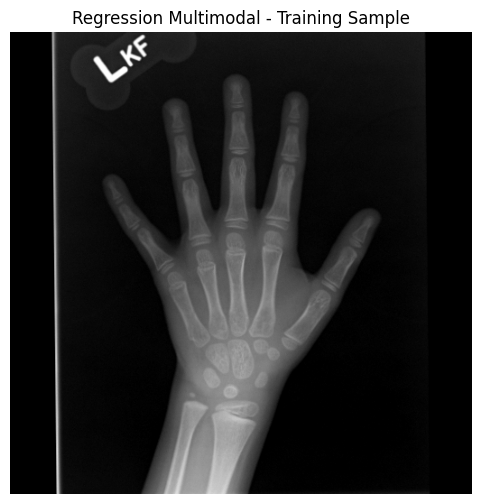

In [60]:
import matplotlib.pyplot as plt

# Get one sample from each dataset
train_sample = train_dataset[0]
val_sample = val_dataset[0]
test_sample = test_dataset[0]

# Display sample information
for name, sample in [
    ("Training", train_sample),
    ("Validation", val_sample),
    ("Testing", test_sample)
]:
    print(f"\n{name} sample:")
    print("Image shape:", sample["image"].shape)
    print("Bone age:", sample["bone_age"].item(), "months")
    print("Gender (male=1, female=0):", sample["male"].item())
    print("Image ID:", sample["id"])

# Display training image
image = train_sample["image"].squeeze(0).numpy()

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Regression Multimodal - Training Sample")
plt.axis("off")
plt.show()

In [61]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 1259
Validation batches: 158
Testing batches: 158


In [62]:
batch = next(iter(train_loader))

print("Image batch shape:", batch["image"].shape)
print("Bone age batch shape:", batch["bone_age"].shape)
print("Gender batch shape:", batch["male"].shape)

print("Image dtype:", batch["image"].dtype)
print("Bone age dtype:", batch["bone_age"].dtype)
print("Gender dtype:", batch["male"].dtype)

Image batch shape: torch.Size([8, 1, 512, 512])
Bone age batch shape: torch.Size([8])
Gender batch shape: torch.Size([8])
Image dtype: torch.float32
Bone age dtype: torch.float32
Gender dtype: torch.float32


In [63]:
%cd /content/Bonetest

import inspect
import sys

sys.path.insert(0, "/content/Bonetest/backend")

from app.models.regression_multimodal import RegressionMultimodal

# Display model implementation
print("========== REGRESSION MULTIMODAL MODEL ==========")

print(inspect.getsource(RegressionMultimodal))

/content/Bonetest
========== REGRESSION MULTIMODAL MODEL ==========
class RegressionMultimodal(nn.Module):
    """Regression-based multimodal model using image and gender metadata."""

    def __init__(self, pretrained: bool = False, meta_dim: int = 1) -> None:
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        backbone = models.resnet18(weights=weights)
        _adapt_resnet_input_conv(backbone)
        self.feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.image_backbone = backbone

        self.meta_encoder = nn.Sequential(
            nn.Linear(meta_dim, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 64),
            nn.ReLU(inplace=True),
        )

        self.fusion_head = nn.Sequential(
            nn.Linear(self.feature_dim + 64, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(256, 128),

In [64]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = RegressionMultimodal(
    pretrained=True,
    meta_dim=1
).to(DEVICE)

print("Model initialized successfully!")
print("Device:", DEVICE)

print("\nTotal parameters:",
      sum(p.numel() for p in model.parameters()))

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

print("\nModel architecture:")
print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 127MB/s]


Model initialized successfully!
Device: cuda

Total parameters: 11356033
Trainable parameters: 11356033

Model architecture:
RegressionMultimodal(
  (image_backbone): ResNet(
    (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBl

In [65]:
import torch

model.eval()

# Get one batch
batch = next(iter(train_loader))

images = batch["image"].to(DEVICE)
gender = batch["male"].to(DEVICE)
targets = batch["bone_age"].to(DEVICE)

# Run prediction without calculating gradients
with torch.no_grad():
    predictions = model(images, gender)

print("Forward pass successful!")
print("Input image shape:", images.shape)
print("Input gender shape:", gender.shape)
print("Target shape:", targets.shape)
print("Prediction shape:", predictions.shape)

print("\nActual bone ages:", targets[:5].cpu().numpy())
print("Predicted bone ages:", predictions[:5].cpu().numpy())

Forward pass successful!
Input image shape: torch.Size([8, 1, 512, 512])
Input gender shape: torch.Size([8])
Target shape: torch.Size([8])
Prediction shape: torch.Size([8])

Actual bone ages: [144. 156. 132. 144.  60.]
Predicted bone ages: [-0.13427283 -0.12225421 -0.14809589 -0.13511394 -0.12679984]


In [66]:
import torch
import torch.nn as nn
import torch.optim as optim

# Training configuration
MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 6

LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001

# Loss function
criterion = nn.SmoothL1Loss(beta=1.0)

# Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Training configuration created successfully!")
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Scheduler:", scheduler.__class__.__name__)

Training configuration created successfully!
Loss function: SmoothL1Loss()
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Maximum epochs: 30
Early stopping patience: 6
Scheduler: ReduceLROnPlateau


In [67]:
from google.colab import drive
from pathlib import Path
import os

# Mount Google Drive if it is not already mounted
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")

# Output directory
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/BoneTest/Regression_Multimodal"
)

# Create folders
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PLOT_DIR = OUTPUT_DIR / "plots"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Best model checkpoint
BEST_MODEL_PATH = CHECKPOINT_DIR / "best_regression_multimodal.pth"

print("Output directories prepared successfully!")
print("Output directory:", OUTPUT_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Plot directory:", PLOT_DIR)
print("Best model path:", BEST_MODEL_PATH)

Output directories prepared successfully!
Output directory: /content/drive/MyDrive/BoneTest/Regression_Multimodal
Checkpoint directory: /content/drive/MyDrive/BoneTest/Regression_Multimodal/checkpoints
Plot directory: /content/drive/MyDrive/BoneTest/Regression_Multimodal/plots
Best model path: /content/drive/MyDrive/BoneTest/Regression_Multimodal/checkpoints/best_regression_multimodal.pth


In [68]:
# Store training and validation metrics
history = {
    "train_loss": [],
    "val_loss": [],
    "train_mae": [],
    "val_mae": [],
    "learning_rate": []
}

best_val_mae = float("inf")
epochs_without_improvement = 0

print("Training history initialized!")
print("Initial best validation MAE:", best_val_mae)
print("Early stopping counter:", epochs_without_improvement)

Training history initialized!
Initial best validation MAE: inf
Early stopping counter: 0


In [69]:
import torch
import numpy as np

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    absolute_errors = []

    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        gender = batch["male"].to(device, non_blocking=True)
        targets = batch["bone_age"].to(device, non_blocking=True)

        optimizer.zero_grad()

        predictions = model(images, gender)
        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        errors = torch.abs(predictions.detach() - targets)
        absolute_errors.extend(errors.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_mae = float(np.mean(absolute_errors))

    return epoch_loss, epoch_mae


def validate_one_epoch(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    absolute_errors = []

    with torch.no_grad():
        for batch in loader:
            images = batch["image"].to(device, non_blocking=True)
            gender = batch["male"].to(device, non_blocking=True)
            targets = batch["bone_age"].to(device, non_blocking=True)

            predictions = model(images, gender)
            loss = criterion(predictions, targets)

            running_loss += loss.item() * images.size(0)

            errors = torch.abs(predictions - targets)
            absolute_errors.extend(errors.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_mae = float(np.mean(absolute_errors))

    return epoch_loss, epoch_mae


print("Training and validation functions created successfully!")

Training and validation functions created successfully!


In [70]:
test_train_loss, test_train_mae = train_one_epoch(
    model, train_loader, criterion, optimizer, DEVICE
)

test_val_loss, test_val_mae = validate_one_epoch(
    model, val_loader, criterion, DEVICE
)

print("One-epoch test completed!")
print("Training Loss:", test_train_loss)
print("Training MAE:", test_train_mae, "months")
print("Validation Loss:", test_val_loss)
print("Validation MAE:", test_val_mae, "months")

One-epoch test completed!
Training Loss: 122.41963980867601
Training MAE: 122.91959381103516 months
Validation Loss: 118.87923719240996
Validation MAE: 119.37914276123047 months


In [71]:
import torch

# Record the completed test epoch as Epoch 1
history["train_loss"].append(test_train_loss)
history["train_mae"].append(test_train_mae)
history["val_loss"].append(test_val_loss)
history["val_mae"].append(test_val_mae)
history["learning_rate"].append(optimizer.param_groups[0]["lr"])

best_val_mae = test_val_mae
epochs_without_improvement = 0
completed_epoch = 1

# Update learning-rate scheduler
scheduler.step(test_val_mae)

# Create checkpoint
checkpoint = {
    "epoch": completed_epoch,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "best_val_mae": best_val_mae,
    "epochs_without_improvement": epochs_without_improvement,
    "history": history,
    "model_type": "regression_multimodal",
    "norm_mean": 0.4523,
    "norm_std": 0.2118
}

# Save both best and latest checkpoints
torch.save(checkpoint, BEST_MODEL_PATH)
torch.save(checkpoint, CHECKPOINT_DIR / "latest_checkpoint.pth")

print("Epoch 1 checkpoint saved successfully!")
print("Best validation MAE:", best_val_mae)
print("Completed epochs:", completed_epoch)
print("Best checkpoint:", BEST_MODEL_PATH)
print("Latest checkpoint:", CHECKPOINT_DIR / "latest_checkpoint.pth")

Epoch 1 checkpoint saved successfully!
Best validation MAE: 119.37914276123047
Completed epochs: 1
Best checkpoint: /content/drive/MyDrive/BoneTest/Regression_Multimodal/checkpoints/best_regression_multimodal.pth
Latest checkpoint: /content/drive/MyDrive/BoneTest/Regression_Multimodal/checkpoints/latest_checkpoint.pth


In [72]:

import torch
import json
import os
from pathlib import Path

LATEST_CHECKPOINT_PATH = CHECKPOINT_DIR / "latest_checkpoint.pth"
HISTORY_PATH = OUTPUT_DIR / "training_history.json"

# Confirm that Epoch 1 recovery checkpoint exists
assert LATEST_CHECKPOINT_PATH.exists(), (
    "Latest checkpoint missing. Save Epoch 1 checkpoint first."
)

print("Starting Regression Multimodal training...")
print("Maximum epochs:", MAX_EPOCHS)
print("Starting from epoch:", completed_epoch + 1)

for epoch in range(completed_epoch + 1, MAX_EPOCHS + 1):

    current_lr = optimizer.param_groups[0]["lr"]

    print(f"\n{'='*55}")
    print(f"Epoch {epoch}/{MAX_EPOCHS}")
    print(f"Learning rate: {current_lr:.7f}")
    print(f"{'='*55}")

    # Training
    train_loss, train_mae = train_one_epoch(
        model, train_loader, criterion, optimizer, DEVICE
    )

    # Validation
    val_loss, val_mae = validate_one_epoch(
        model, val_loader, criterion, DEVICE
    )

    # Update history
    history["train_loss"].append(train_loss)
    history["train_mae"].append(train_mae)
    history["val_loss"].append(val_loss)
    history["val_mae"].append(val_mae)
    history["learning_rate"].append(current_lr)

    # Check whether validation MAE improved
    improved = val_mae < best_val_mae

    if improved:
        best_val_mae = val_mae
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Update scheduler
    scheduler.step(val_mae)

    # Prepare checkpoint
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_mae": best_val_mae,
        "epochs_without_improvement": epochs_without_improvement,
        "history": history,
        "model_type": "regression_multimodal",
        "norm_mean": 0.4523,
        "norm_std": 0.2118
    }

    # Save latest checkpoint after every epoch
    temp_path = str(LATEST_CHECKPOINT_PATH) + ".tmp"
    torch.save(checkpoint, temp_path)
    os.replace(temp_path, LATEST_CHECKPOINT_PATH)

    # Save best model separately
    if improved:
        torch.save(checkpoint, BEST_MODEL_PATH)
        print("New best model saved!")

    # Save training history
    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=4)

    completed_epoch = epoch

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training MAE: {train_mae:.4f} months")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation MAE: {val_mae:.4f} months")
    print(f"Best Validation MAE: {best_val_mae:.4f} months")
    print(f"Epochs without improvement: {epochs_without_improvement}")
    print(f"Checkpoint saved for epoch {epoch}")

    # Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping activated!")
        print("Validation MAE did not improve for 6 consecutive epochs.")
        break

print("\nTraining process finished or stopped.")
print("Last completed epoch:", completed_epoch)
print("Best validation MAE:", best_val_mae)
print("Best model:", BEST_MODEL_PATH)
print("Latest checkpoint:", LATEST_CHECKPOINT_PATH)


Starting Regression Multimodal training...
Maximum epochs: 30
Starting from epoch: 2

Epoch 2/30
Learning rate: 0.0001000
New best model saved!
Training Loss: 108.6368
Training MAE: 109.1365 months
Validation Loss: 100.7595
Validation MAE: 101.2590 months
Best Validation MAE: 101.2590 months
Epochs without improvement: 0
Checkpoint saved for epoch 2

Epoch 3/30
Learning rate: 0.0001000
New best model saved!
Training Loss: 89.3510
Training MAE: 89.8503 months
Validation Loss: 87.1982
Validation MAE: 87.6980 months
Best Validation MAE: 87.6980 months
Epochs without improvement: 0
Checkpoint saved for epoch 3

Epoch 4/30
Learning rate: 0.0001000
New best model saved!
Training Loss: 68.1772
Training MAE: 68.6762 months
Validation Loss: 56.8535
Validation MAE: 57.3525 months
Best Validation MAE: 57.3525 months
Epochs without improvement: 0
Checkpoint saved for epoch 4

Epoch 5/30
Learning rate: 0.0001000
New best model saved!
Training Loss: 48.8902
Training MAE: 49.3887 months
Validation Lo

KeyboardInterrupt: 

In [73]:
import torch

checkpoint_path = CHECKPOINT_DIR / "latest_checkpoint.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Last saved epoch:", checkpoint["epoch"])
print("Best validation MAE:", checkpoint["best_val_mae"])
print("Training history epochs:", len(checkpoint["history"]["val_mae"]))

Last saved epoch: 20
Best validation MAE: 10.677873611450195
Training history epochs: 20


In [74]:
import torch

best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

print("Best Regression Multimodal model loaded!")
print("Best epoch:", best_checkpoint["epoch"])
print("Best validation MAE:", best_checkpoint["best_val_mae"])

Best Regression Multimodal model loaded!
Best epoch: 17
Best validation MAE: 10.677873611450195


In [75]:

import torch
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

model.eval()

all_predictions = []
all_targets = []
all_genders = []
all_ids = []

with torch.no_grad():
    for batch in test_loader:
        images = batch["image"].to(DEVICE)
        gender = batch["male"].to(DEVICE)
        targets = batch["bone_age"].to(DEVICE)

        predictions = model(images, gender)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())
        all_genders.extend(gender.cpu().numpy())
        all_ids.extend(batch["id"])

# Convert to NumPy arrays
y_true = np.array(all_targets)
y_pred = np.array(all_predictions)

# Calculate evaluation metrics
test_mae = mean_absolute_error(y_true, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
test_median_ae = median_absolute_error(y_true, y_pred)
test_r2 = r2_score(y_true, y_pred)

print("========== TEST SET EVALUATION ==========")
print(f"MAE: {test_mae:.4f} months")
print(f"RMSE: {test_rmse:.4f} months")
print(f"Median Absolute Error: {test_median_ae:.4f} months")
print(f"R2 Score: {test_r2:.4f}")
print("Number of test samples:", len(y_true))


========== TEST SET EVALUATION ==========
MAE: 11.1889 months
RMSE: 14.3762 months
Median Absolute Error: 9.4548 months
R2 Score: 0.8751
Number of test samples: 1259


In [76]:

import os
import json
import pandas as pd
import numpy as np

# Prepare evaluation results
evaluation_results = {
    "model": "Regression Multimodal",
    "best_epoch": int(best_checkpoint["epoch"]),
    "best_validation_mae": float(best_checkpoint["best_val_mae"]),
    "test_mae": float(test_mae),
    "test_rmse": float(test_rmse),
    "test_median_absolute_error": float(test_median_ae),
    "test_r2_score": float(test_r2),
    "number_of_test_samples": int(len(y_true))
}

# Save metrics as JSON
evaluation_path = os.path.join(
    OUTPUT_DIR,
    "evaluation_results.json"
)

with open(evaluation_path, "w") as file:
    json.dump(evaluation_results, file, indent=4)

# Prepare individual predictions
predictions_df = pd.DataFrame({
    "image_id": all_ids,
    "actual_bone_age_months": y_true,
    "predicted_bone_age_months": y_pred,
    "absolute_error_months": np.abs(y_true - y_pred),
    "gender_male": all_genders
})

# Save predictions as CSV
predictions_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

print("Results saved successfully!")
print("Evaluation metrics:", evaluation_path)
print("Test predictions:", predictions_path)
print("Total predictions saved:", len(predictions_df))

display(predictions_df.head())


Results saved successfully!
Evaluation metrics: /content/drive/MyDrive/BoneTest/Regression_Multimodal/evaluation_results.json
Test predictions: /content/drive/MyDrive/BoneTest/Regression_Multimodal/test_predictions.csv
Total predictions saved: 1259


,image_id,actual_bone_age_months,predicted_bone_age_months,absolute_error_months,gender_male
0,2228,132.0,144.434998,12.434998,0.0
1,8223,106.0,98.895508,7.104492,0.0
2,11812,60.0,69.873466,9.873466,0.0
3,10856,82.0,87.539558,5.539558,0.0
4,5711,174.0,158.887756,15.112244,1.0


In [77]:
print("Training history keys:")
print(history.keys())

print("\nNumber of epochs recorded:")
for key, values in history.items():
    print(f"{key}: {len(values)} values")

Training history keys:
dict_keys(['train_loss', 'val_loss', 'train_mae', 'val_mae', 'learning_rate'])

Number of epochs recorded:
train_loss: 20 values
val_loss: 20 values
train_mae: 20 values
val_mae: 20 values
learning_rate: 20 values


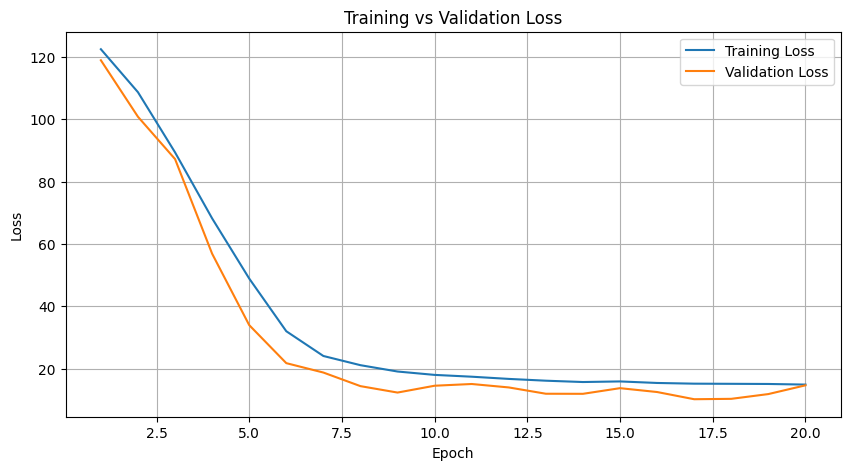

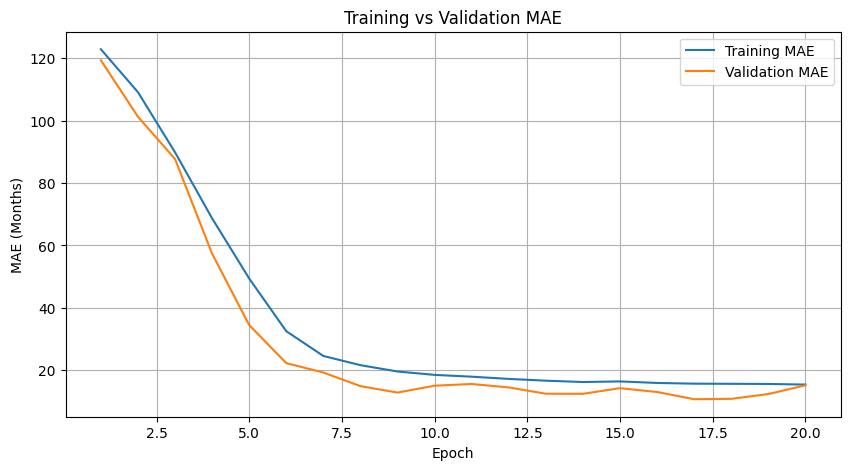

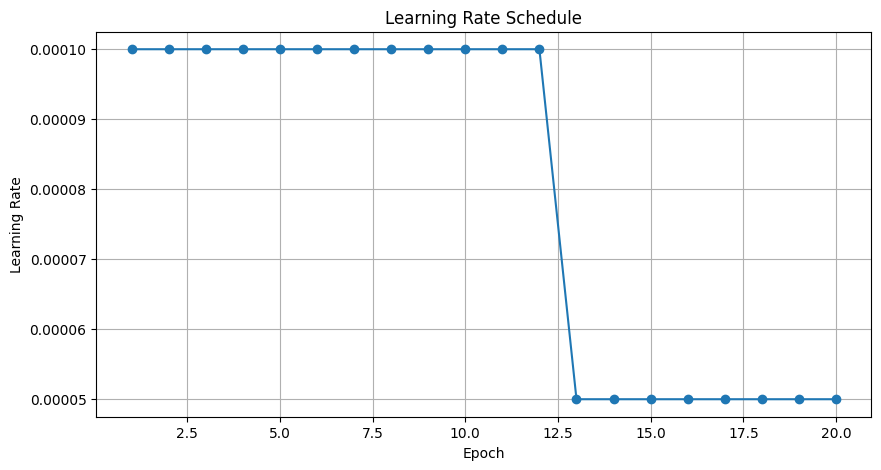

All training graphs saved successfully!
Plot directory: /content/drive/MyDrive/BoneTest/Regression_Multimodal/plots
Files: ['loss_curve.png', 'mae_curve.png', 'learning_rate_curve.png']


In [78]:
import matplotlib.pyplot as plt
import os

epochs = range(1, len(history["train_loss"]) + 1)

# 1. Training vs Validation Loss
plt.figure(figsize=(10, 5))
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(PLOT_DIR, "loss_curve.png"), dpi=300, bbox_inches="tight")
plt.show()

# 2. Training vs Validation MAE
plt.figure(figsize=(10, 5))
plt.plot(epochs, history["train_mae"], label="Training MAE")
plt.plot(epochs, history["val_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (Months)")
plt.title("Training vs Validation MAE")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(PLOT_DIR, "mae_curve.png"), dpi=300, bbox_inches="tight")
plt.show()

# 3. Learning Rate
plt.figure(figsize=(10, 5))
plt.plot(epochs, history["learning_rate"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate Schedule")
plt.grid(True)
plt.savefig(os.path.join(PLOT_DIR, "learning_rate_curve.png"), dpi=300, bbox_inches="tight")
plt.show()

print("All training graphs saved successfully!")
print("Plot directory:", PLOT_DIR)
print("Files:", os.listdir(PLOT_DIR))

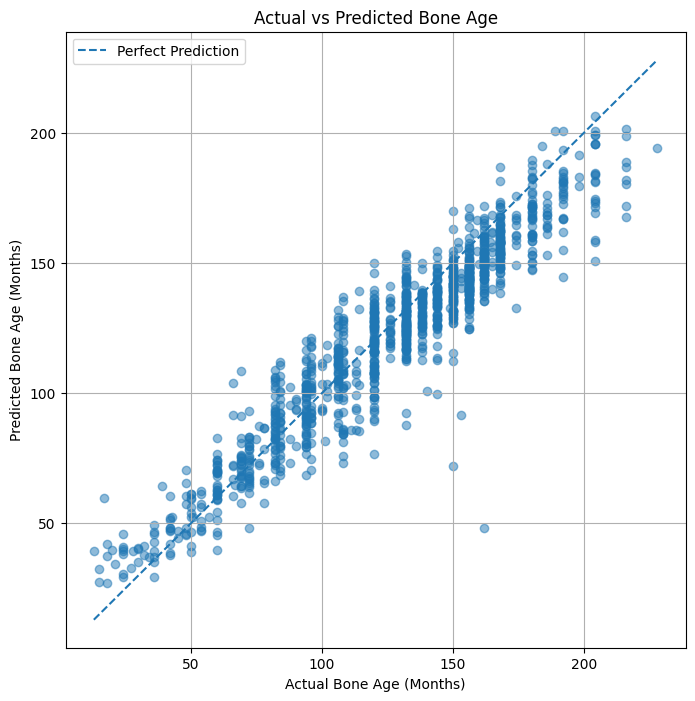

Actual vs Predicted graph saved successfully!


In [79]:
import matplotlib.pyplot as plt
import numpy as np
import os

plt.figure(figsize=(8, 8))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.5
)

# Ideal prediction line
min_value = min(y_true.min(), y_pred.min())
max_value = max(y_true.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Bone Age (Months)")
plt.ylabel("Predicted Bone Age (Months)")
plt.title("Actual vs Predicted Bone Age")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(PLOT_DIR, "actual_vs_predicted.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Actual vs Predicted graph saved successfully!")

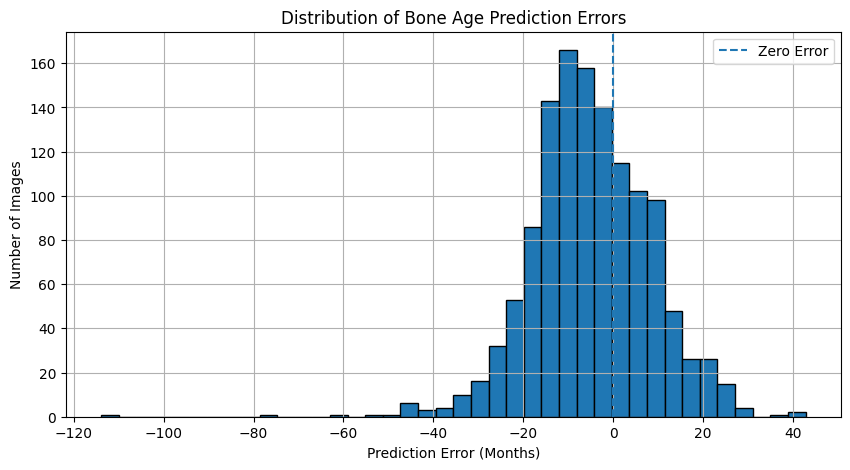

Prediction error distribution saved successfully!
Mean error: -4.9397 months
Standard deviation: 13.5009 months


In [80]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Calculate prediction errors
errors = y_pred - y_true

plt.figure(figsize=(10, 5))

plt.hist(
    errors,
    bins=40,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    label="Zero Error"
)

plt.xlabel("Prediction Error (Months)")
plt.ylabel("Number of Images")
plt.title("Distribution of Bone Age Prediction Errors")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(PLOT_DIR, "prediction_error_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Prediction error distribution saved successfully!")
print("Mean error:", round(np.mean(errors), 4), "months")
print("Standard deviation:", round(np.std(errors), 4), "months")

In [81]:
import json
import os

# Save training history
training_history_path = os.path.join(
    OUTPUT_DIR,
    "training_history.json"
)

with open(training_history_path, "w") as f:
    json.dump(history, f, indent=4)

# Save final evaluation metrics
evaluation_results = {
    "model": "Regression Multimodal",
    "best_epoch": int(best_checkpoint["epoch"]),
    "best_validation_mae": float(best_checkpoint["best_val_mae"]),
    "test_metrics": {
        "MAE_months": float(test_mae),
        "RMSE_months": float(test_rmse),
        "Median_Absolute_Error_months": float(test_median_ae),
        "R2_Score": float(test_r2),
        "test_samples": int(len(y_true))
    }
}

evaluation_path = os.path.join(
    OUTPUT_DIR,
    "evaluation_results.json"
)

with open(evaluation_path, "w") as f:
    json.dump(evaluation_results, f, indent=4)

print("Training history saved:", training_history_path)
print("Evaluation results saved:", evaluation_path)

print("\nAll plot files:")
for file in sorted(os.listdir(PLOT_DIR)):
    print(file)

Training history saved: /content/drive/MyDrive/BoneTest/Regression_Multimodal/training_history.json
Evaluation results saved: /content/drive/MyDrive/BoneTest/Regression_Multimodal/evaluation_results.json

All plot files:
actual_vs_predicted.png
learning_rate_curve.png
loss_curve.png
mae_curve.png
prediction_error_distribution.png


In [82]:
import os
import torch

print("========== FINAL MODEL VERIFICATION ==========")

for path in [BEST_MODEL_PATH, LATEST_CHECKPOINT_PATH]:
    if os.path.exists(path):
        print("\nFile:", os.path.basename(path))
        print("Status: Saved successfully")
        print("Size:", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")
    else:
        print("\nMissing:", path)

# Verify best checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nBest Model Details")
print("Model type:", checkpoint["model_type"])
print("Best epoch:", checkpoint["epoch"])
print("Best validation MAE:", checkpoint["best_val_mae"])

print("\nVerification completed!")

========== FINAL MODEL VERIFICATION ==========

File: best_regression_multimodal.pth
Status: Saved successfully
Size: 130.11 MB

File: latest_checkpoint.pth
Status: Saved successfully
Size: 130.11 MB

Best Model Details
Model type: regression_multimodal
Best epoch: 17
Best validation MAE: 10.677873611450195

Verification completed!


In [83]:
%cd /content/Bonetest

!git status
!git branch --show-current
!git remote -v

/content/Bonetest
On branch train/regression-multimodal
Your branch is up to date with 'upstream/bonetest-model-improvements'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	kaggle (1).json

nothing added to commit but untracked files present (use "git add" to track)
train/regression-multimodal
origin	https://github.com/trishakunder/Bonetest.git (fetch)
origin	https://github.com/trishakunder/Bonetest.git (push)
upstream	https://github.com/manyaa133/Bonetest.git (fetch)
upstream	https://github.com/manyaa133/Bonetest.git (push)


In [84]:
%cd /content/Bonetest

print("Notebook files:")
!find . -maxdepth 3 -name "*.ipynb" -not -path "./.git/*"

print("\nRepository files:")
!ls -la

/content/Bonetest
Notebook files:
./legacy/validator_2class/train_validator_colab.ipynb
./notebooks/train_efficientnet_kaggle.ipynb
./notebooks/train_three_models_colab.ipynb
./notebooks/train_colab.ipynb

Repository files:
total 836
drwxr-xr-x 13 root root   4096 Nov 19 14:16  .
drwxr-xr-x  1 root root   4096 Nov 19 14:18  ..
drwxr-xr-x 10 root root   4096 Nov 19 13:59  backend
-rw-r--r--  1 root root  13842 Nov 19 13:59  BONETEST_BUG_FIX_REPORT.md
-rw-r--r--  1 root root 615981 Nov 19 13:59  bonetest_colab_bundle.zip
-rw-r--r--  1 root root  64321 Nov 19 13:59  BONETEST_COMPLETE_TECHNICAL_DOCUMENTATION.md
-rw-r--r--  1 root root  14326 Nov 19 13:59  BONETEST_FINAL_MODEL_REPORT.md
-rw-r--r--  1 root root  17910 Nov 19 13:59  BONETEST_MODEL_EXPERIMENTS.md
-rw-r--r--  1 root root   9684 Nov 19 13:59  BONETEST_SETUP_AND_EXECUTION.md
drwxr-xr-x  2 root root   4096 Nov 19 13:59  configs
-rw-r--r--  1 root root    369 Nov 19 13:59  docker-compose.yml
drwxr-xr-x  2 root root   4096 Nov 19 13

In [85]:
import json
import os

notebook_files = [
    "notebooks/train_colab.ipynb",
    "notebooks/train_three_models_colab.ipynb",
    "notebooks/train_efficientnet_kaggle.ipynb",
    "legacy/validator_2class/train_validator_colab.ipynb"
]

for path in notebook_files:
    with open(path, "r", encoding="utf-8") as f:
        nb = json.load(f)

    text = "\n".join(
        "".join(cell.get("source", []))
        for cell in nb.get("cells", [])
    )

    print("\nNotebook:", path)
    print("Size:", round(os.path.getsize(path) / 1024, 2), "KB")
    print("RegressionMultimodal:", "RegressionMultimodal" in text)
    print("Training loop:", "train_one_epoch" in text)
    print("Evaluation:", "test_mae" in text)


Notebook: notebooks/train_colab.ipynb
Size: 1.8 KB
RegressionMultimodal: False
Training loop: False
Evaluation: False

Notebook: notebooks/train_three_models_colab.ipynb
Size: 26.42 KB
RegressionMultimodal: True
Training loop: False
Evaluation: False

Notebook: notebooks/train_efficientnet_kaggle.ipynb
Size: 6.77 KB
RegressionMultimodal: False
Training loop: False
Evaluation: False

Notebook: legacy/validator_2class/train_validator_colab.ipynb
Size: 19.07 KB
RegressionMultimodal: False
Training loop: False
Evaluation: False


In [86]:
import json

path = "notebooks/train_three_models_colab.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if source.strip():
        print(f"\n--- CELL {i} ({cell['cell_type']}) ---")
        print(source[:350])


--- CELL 0 (markdown) ---
# BoneTest — Colab GPU Training for `multiscale_cnn_rf`, `ensemble_cnn`, and `regression_multimodal`

This notebook trains the three remaining BoneTest models strictly on the frozen, deduplicated, joint-stratified RSNA split manifests (`train_manifest.csv` [$N=10,068$] and `val_manifest.csv` [$N=1,259$]), **without ever touching `test_manifest.csv`

--- CELL 1 (code) ---
# 1. Mount Google Drive & Verify GPU
import os
from pathlib import Path
import torch

from google.colab import drive
drive.mount('/content/drive')

assert torch.cuda.is_available(), 'Please enable GPU in Colab: Runtime -> Change runtime type -> T4 GPU'
DEVICE = torch.device('cuda')
print('Using GPU:', torch.cuda.get_device_name(0))

DRIVE_ROOT = Pa

--- CELL 2 (code) ---
# 2. Configure Input Paths (Code, Split Manifests, normalization.json, and RSNA Images)
import json
import sys
import zipfile
import pandas as pd

BUNDLE_ZIP = Path('/content/drive/MyDrive/bonetest_colab_bundle.zip')
WORK_DIR

In [87]:
%cd /content/Bonetest

# Confirm correct branch
!git checkout train/regression-multimodal

# Stage only the training notebook
!git add notebooks/train_regression_multimodal_colab.ipynb

# Commit
!git commit -m "Add regression multimodal training notebook"

# Push to your GitHub fork
!git push -u origin train/regression-multimodal

/content/Bonetest
Already on 'train/regression-multimodal'
Your branch is up to date with 'upstream/bonetest-model-improvements'.
fatal: pathspec 'notebooks/train_regression_multimodal_colab.ipynb' did not match any files
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@5a7752925280.(none)')
fatal: could not read Username for 'https://github.com': No such device or address
